# PLDM: planning with a latent dynamics model trained without rewards

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/pldm.ipynb)

[PLDM](https://arxiv.org/abs/2502.14819) ([code](https://github.com/vladisai/PLDM)) learns a JEPA latent dynamics model from reward-free trajectories: an encoder and a recurrent predictor trained on multi-step latent prediction, with VICReg variance and covariance terms, temporal smoothness and inverse dynamics to keep the latents from collapsing. At test time a planner searches for actions whose imagined path ends near the latent of a goal image. Here a macaw learns PLDM's Two-Rooms task: a rock wall with one gap splits the sky, the goal is on the other side, and the only way there is through the gap.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import PLDM, PLDMEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Reward-free data
The macaw flies at random, keeping its previous action with probability 0.8: no rewards, no goals, few crossings of the gap. Episodes are cut into windows of 17 frames, the paper's 16 prediction steps.

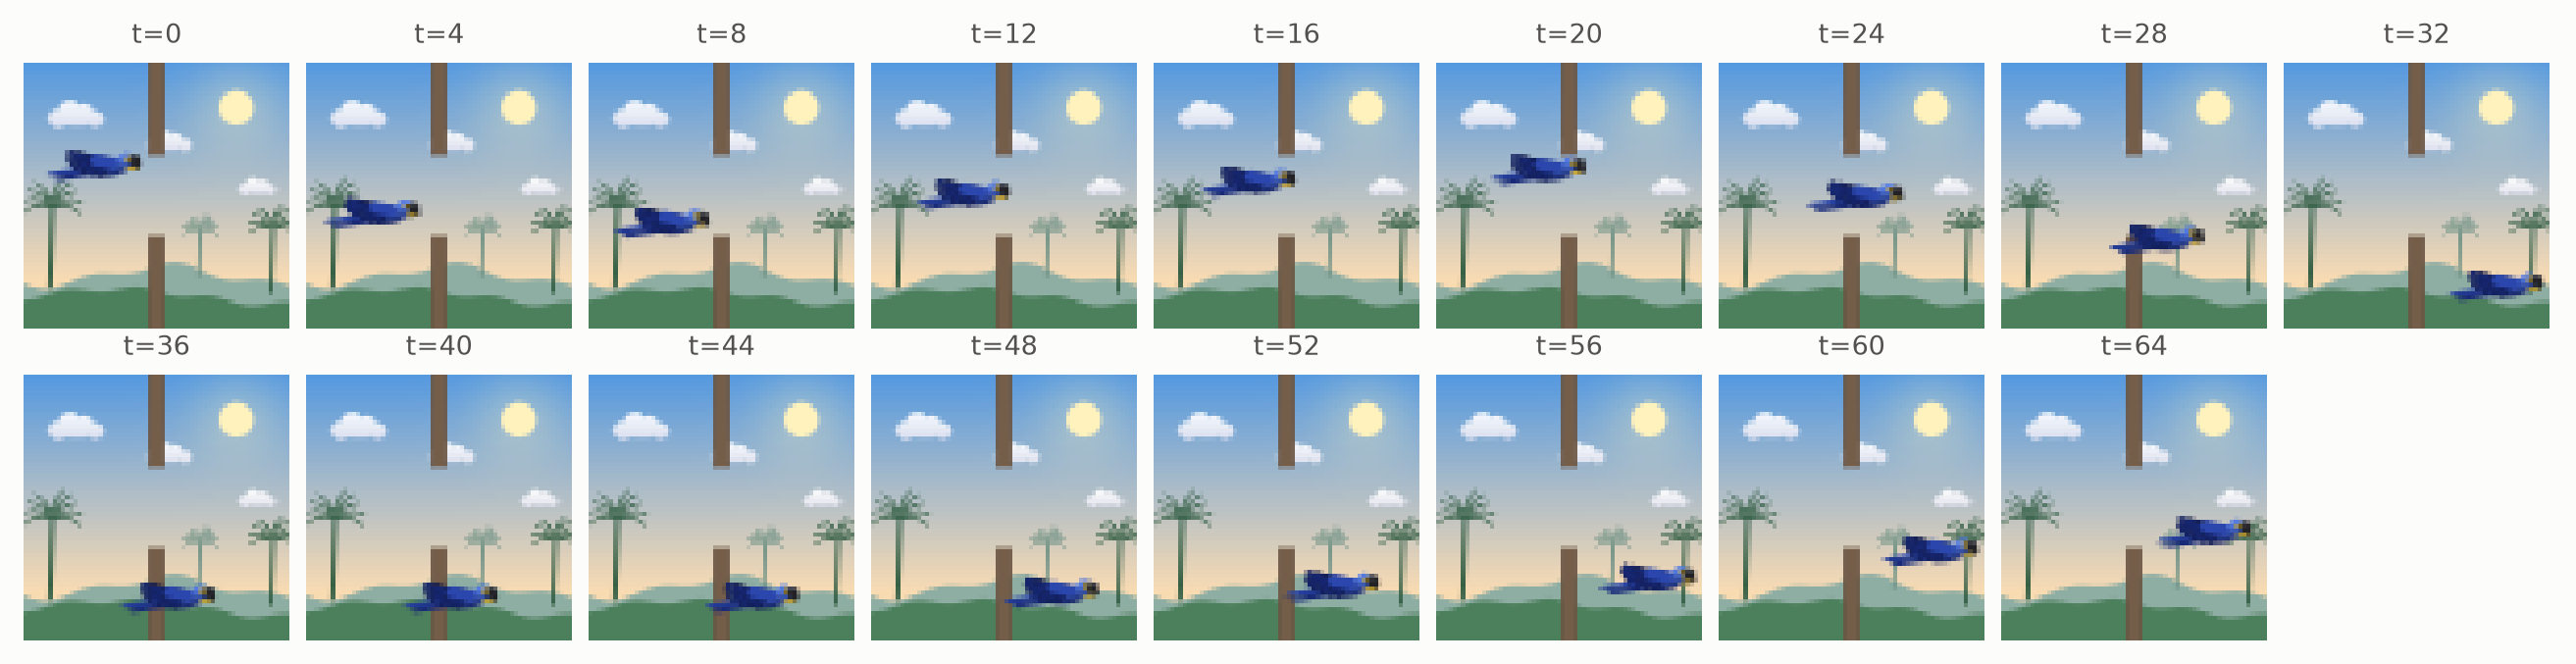

In [3]:
env = Macaw(batch_size=1024, rooms=True, device=device)
data = env.collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=17), batch_size=128, shuffle=True, drop_last=True)
plots.images(data["pixels"][0, ::4].cpu(), [f"t={t}" for t in range(0, 65, 4)], ncols=9)

## Model
A small IMPALA-style encoder maps each 64×64 frame to a 128-d latent, and a GRU whose hidden state is that latent predicts the next one from the action. The loss weights are the reference's Two-Rooms ones.

In [4]:
model = PLDM(PLDMEncoder(img_size=64, latent_dim=128), action_dim=2, latent_dim=128).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

0.54M parameters


## Training
The predictor unrolls open loop from the first frame of each window over all 16 actions, trained with Adam as in the paper.

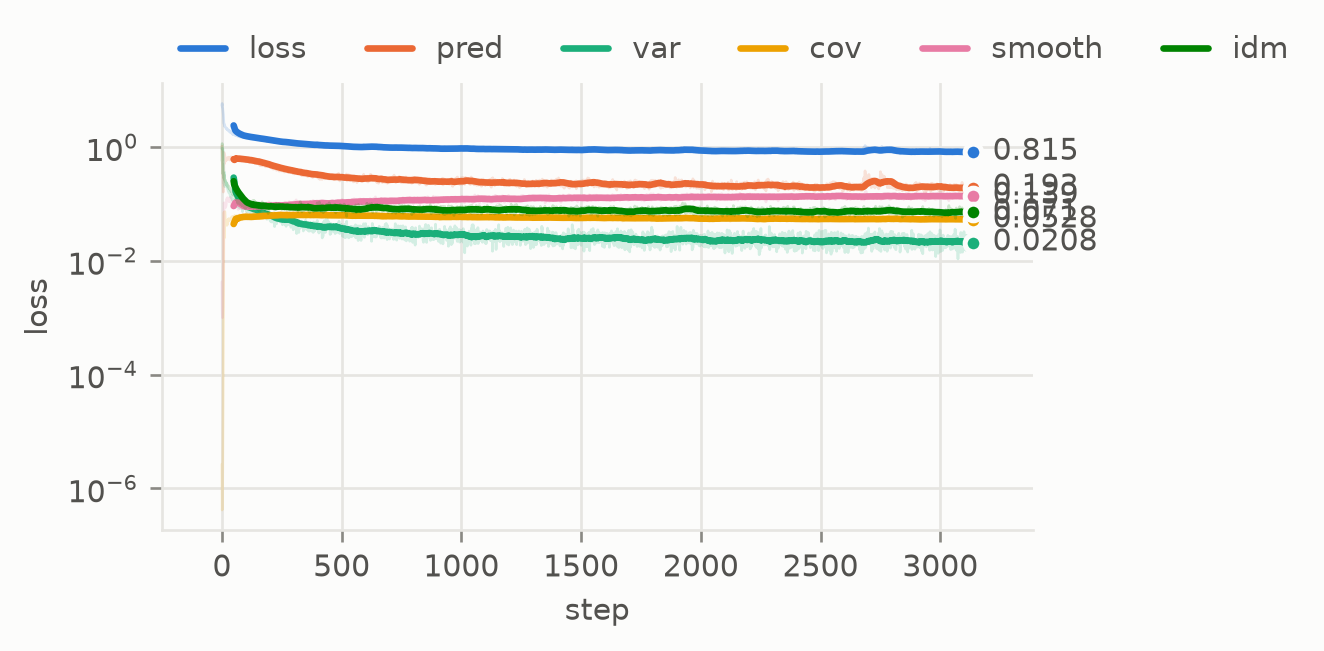

In [5]:
log = fit(model, loader, epochs=8, lr=1e-3, weight_decay=0)
plots.curves(log, smooth=50)

## Plan toward goal images
Each task starts on one side of the wall with the goal image on the other. CEM searches 20-step action sequences and scores each by the mean latent distance to the goal along its imagined path, PLDM's planning cost; the first action runs and the planner replans every step. A greedy controller that knows the true positions and heads straight for the goal shows why the wall matters; random actions are the floor.

                               success  reached   steps  final distance  progress     SPL  smoothness  ms / step
PLDM + CEM            100% [89%, 100%]     100%    6.22          0.0202     0.959   0.384       0.328        118
greedy (true state)     38% [23%, 55%]      38%     3.5           0.213     0.526   0.365      0.0147     0.0284
random actions          28% [16%, 45%]      28%    29.3           0.445   -0.0455  0.0274        1.03     0.0878


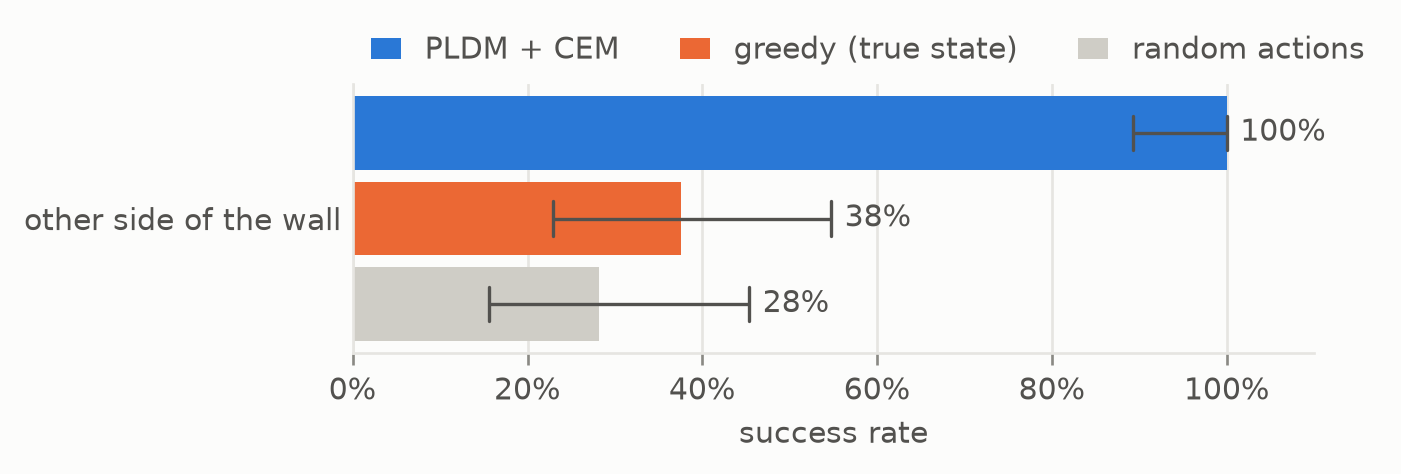

In [6]:
planner = CEM(horizon=20, action_dim=2, num_samples=256, num_elites=32, iterations=6, bounds=(-1, 1), objective="path")

tasks = Macaw(batch_size=32, rooms=True, device=device)
start, goal = tasks.tasks(generator=torch.Generator().manual_seed(1))
policies = {
    "PLDM + CEM": evaluation.goal_policy(model, planner, tasks.render(goal)),
    "greedy (true state)": lambda obs: ((goal - tasks.state) / tasks.max_step).clamp(-1, 1),
    "random actions": evaluation.random_policy(tasks),
}
run = evaluation.goal_reaching(tasks, policies, start, goal, steps=60, success="reached")
print(run)
plots.bars({"other side of the wall": run.intervals()}, xlabel="success rate", baseline="random actions")

Paths of the planner over the goal images; the darker, the later:

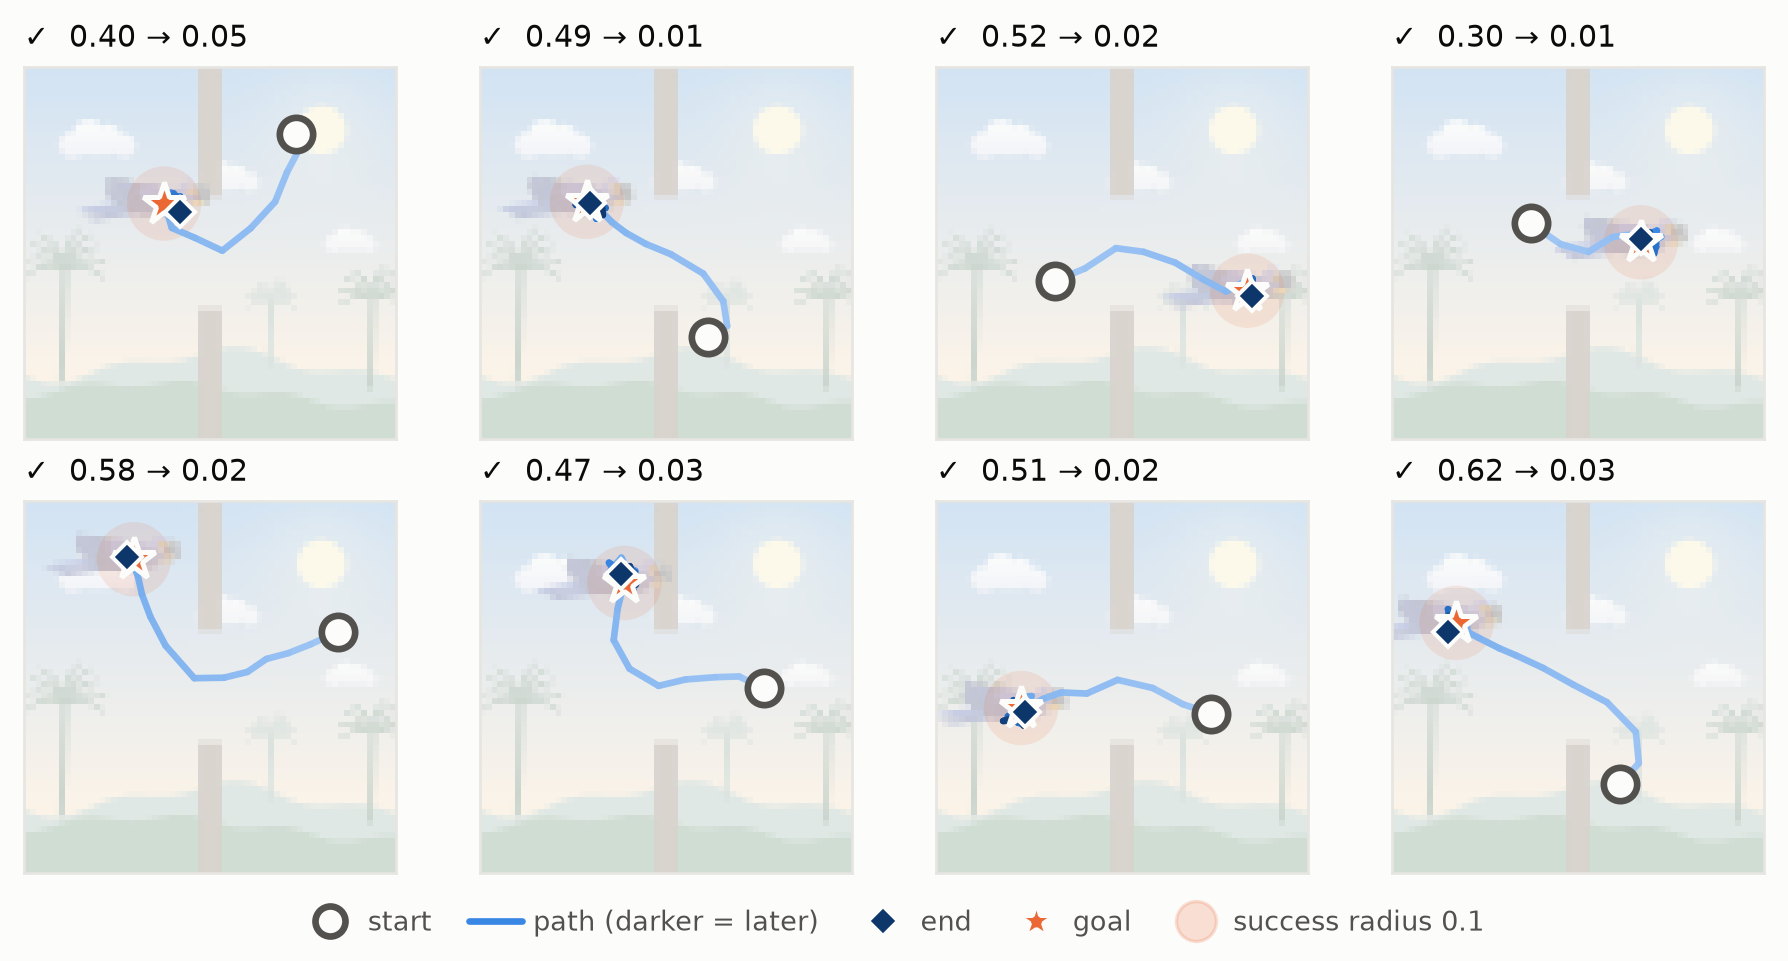

In [7]:
won = run.success["PLDM + CEM"][:8]
plots.trajectories(
    run.paths["PLDM + CEM"][:8], goal[:8], radius=tasks.radius, background=tasks.render(goal[:8]), success=won
)

## Summary
PLDM learns a latent space and its dynamics from reward-free, low-quality trajectories, with no decoder and no target network: multi-step prediction makes the latents predictable, and the variance, covariance, smoothness and inverse-dynamics terms keep them informative. Because the dynamics model knows the wall, a planner minimizing latent distance along the imagined path can route through the gap, where heading straight for the goal gets stuck. The paper plans with MPPI and an ensemble of predictors; this notebook uses CEM with the same path cost and a single predictor.